# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [9]:
import re
import time
import statistics
import sys
import subprocess
import importlib.util
from pathlib import Path

# Instala dependencias que el notebook necesita si faltan en el kernel actual.
def ensure_package(module_name, package_name=None):
    if importlib.util.find_spec(module_name) is None:
        package_name = package_name or module_name
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
        except Exception as exc:
            raise RuntimeError(
                f"No se pudo instalar {package_name} en este kernel. "
                f"Instálelo con {sys.executable} -m pip install {package_name} y vuelva a ejecutar esta celda."
            ) from exc

ensure_package("nltk")
ensure_package("pandas")
ensure_package("numpy")
ensure_package("matplotlib")

import nltk
from nltk.corpus import gutenberg

# Preprocesamiento único para todos los experimentos: minúsculas,
# conservar solo secuencias de letras Unicode; números y puntuación separan tokens.
try:
    DOC_IDS = gutenberg.fileids()
except LookupError:
    if not nltk.download("gutenberg", quiet=True):
        raise RuntimeError("No se pudo descargar el corpus Gutenberg. Revise la conexión a internet y vuelva a ejecutar esta celda.")
    DOC_IDS = gutenberg.fileids()

def tokenize(text):
    return re.findall(r"[^\W\d_]+(?:['’][^\W\d_]+)?", text.lower(), flags=re.UNICODE)

raw_docs = {doc_id: gutenberg.raw(doc_id) for doc_id in DOC_IDS}
documents = {doc_id: tokenize(text) for doc_id, text in raw_docs.items()}
print(f"Documentos: {len(documents)}")
print("Tamaños (tokens):")
for doc_id, tokens in documents.items():
    print(f"{doc_id:35} {len(tokens):>10,}")
print(f"Tokens totales: {sum(map(len, documents.values())):,}")

Documentos: 18
Tamaños (tokens):
austen-emma.txt                        160,994
austen-persuasion.txt                   83,616
austen-sense.txt                       119,912
bible-kjv.txt                          790,052
blake-poems.txt                          6,837
bryant-stories.txt                      46,319
burgess-busterbrown.txt                 15,963
carroll-alice.txt                       26,687
chesterton-ball.txt                     82,168
chesterton-brown.txt                    72,389
chesterton-thursday.txt                 58,295
edgeworth-parents.txt                  167,720
melville-moby_dick.txt                 215,970
milton-paradise.txt                     80,085
shakespeare-caesar.txt                  20,459
shakespeare-hamlet.txt                  29,694
shakespeare-macbeth.txt                 17,754
whitman-leaves.txt                     124,017
Tokens totales: 2,118,931


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [10]:
def sequential_search(query, docs=documents):
    """Búsqueda literal con dos lazos for anidados (documento y token)."""
    term = tokenize(query)
    if len(term) != 1:
        raise ValueError("La consulta debe ser exactamente un término")
    term = term[0]
    found = []
    for doc_id, tokens in docs.items():
        for token in tokens:
            if token == term:
                found.append(doc_id)
                break
    return found

# Una consulta frecuente, una infrecuente y una inexistente
QUERY_TERMS = ["love", "whale", "zzzxqvnotincorpus"]
for q in QUERY_TERMS:
    print(f"{q!r}: {len(sequential_search(q))} documentos")

'love': 15 documentos
'whale': 6 documentos
'zzzxqvnotincorpus': 0 documentos


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [11]:
def mean_query_ms(function, query, repetitions=30):
    """Media de 30 consultas; preparación y tokenización del corpus quedan fuera."""
    samples = []
    for _ in range(repetitions):
        start = time.perf_counter_ns()
        function(query)
        samples.append((time.perf_counter_ns() - start) / 1_000_000)
    return statistics.mean(samples)

if "QUERY_TERMS" not in globals() or "sequential_search" not in globals():
    print("Ejecute las celdas desde el inicio del notebook para definir QUERY_TERMS y sequential_search.")
else:
    for q in QUERY_TERMS:
        print(f"{q:25} {mean_query_ms(sequential_search, q):.6f} ms")

love                      51.246400 ms
whale                     284.593443 ms
zzzxqvnotincorpus         514.534380 ms


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [12]:
def build_inverted_index(docs):
    """término -> conjunto de IDs de documentos (índice por presencia)."""
    index = {}
    for doc_id, tokens in docs.items():
        for term in set(tokens):
            index.setdefault(term, set()).add(doc_id)
    return index

inverted_index = build_inverted_index(documents)
all_doc_ids = set(documents)

def index_search(term, index=inverted_index):
    normalized = tokenize(term)
    if len(normalized) != 1:
        raise ValueError("La consulta debe ser exactamente un término")
    return set(index.get(normalized[0], set()))

def boolean_query(expression, index=inverted_index, universe=all_doc_ids):
    """Evalúa expresiones simples de la forma 'término AND|OR|NOT término'.
    NOT unario (p. ej., 'NOT term') complementa respecto al universo de documentos.
    """
    parts = expression.strip().split()
    if len(parts) == 2 and parts[0].upper() == "NOT":
        return set(universe) - index_search(parts[1], index)
    if len(parts) != 3 or parts[1].upper() not in {"AND", "OR", "NOT"}:
        raise ValueError("Use 't1 AND t2', 't1 OR t2', 't1 NOT t2' o 'NOT t1'")
    left, op, right = parts[0], parts[1].upper(), parts[2]
    a, b = index_search(left, index), index_search(right, index)
    if op == "AND": return a & b
    if op == "OR": return a | b
    return a - b  # t1 NOT t2 equivale a t1 AND NOT t2

print(f"Vocabulario: {len(inverted_index):,} términos")
for term in ["love", "whale", "zzzxqvnotincorpus"]:
    postings = sorted(index_search(term))
    print(f"{term}: DF={len(postings)}, postings={postings[:8]}")
for expression in ["love AND sea", "love OR whale", "love NOT whale", "NOT whale"]:
    print(expression, "->", len(boolean_query(expression)), "documentos")

Vocabulario: 43,494 términos
love: DF=15, postings=['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt']
whale: DF=6, postings=['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
zzzxqvnotincorpus: DF=0, postings=[]
love AND sea -> 13 documentos
love OR whale -> 16 documentos
love NOT whale -> 10 documentos
NOT whale -> 12 documentos


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [13]:
if all(name in globals() for name in ("QUERY_TERMS", "sequential_search", "index_search", "mean_query_ms")):
    comparison_rows = []
    for q in QUERY_TERMS:
        seq = set(sequential_search(q))
        inv = index_search(q)
        assert seq == inv, f"Resultados distintos para {q!r}"
        comparison_rows.append({
            "consulta": q, "documentos": len(seq),
            "secuencial_ms": mean_query_ms(sequential_search, q),
            "indice_ms": mean_query_ms(index_search, q),
        })

    import pandas as pd
    small_results = pd.DataFrame(comparison_rows)
    display(small_results)
else:
    print("Ejecute primero las celdas de las Partes A. Esta comparación necesita sus funciones y consultas.")


,consulta,documentos,secuencial_ms,indice_ms
0,love,15,65.667283,0.013507
1,whale,6,282.017660,0.011520
2,zzzxqvnotincorpus,0,356.871880,0.012200


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [14]:
# Parte B: archivo oficial de textos Gutenberg (~11 GB), descargado una sola vez.
# El inventario se guarda en JSON; las siguientes ejecuciones no vuelven a recorrer 30 GB.
# El ZIP oficial contiene un TAR interno; estas funciones leen ambos formatos.
LARGE_SOURCE = Path("data/txt-files.tar.zip")

def gutenberg_id(filename):
    """Extrae el ID de nombres Gutenberg como 1342-0.txt."""
    match = re.search(r"(?:^|/)(\d+)(?:-[^/]*)?\.txt$", filename.replace("\\", "/"), re.IGNORECASE)
    return int(match.group(1)) if match else None

def _text_name(spec):
    return spec[2] if isinstance(spec, tuple) and spec[0] == "tar" else (spec[1] if isinstance(spec, tuple) else spec)

def discover_large_txt(source, progress_every=100_000):
    """Enumera TXT de carpeta, ZIP directo o ZIP que contiene TAR; deduplica por ebook ID."""
    import tarfile, zipfile
    source = Path(source)
    entries = []
    if source.is_dir():
        entries = [str(p) for p in sorted(source.rglob("*.txt")) if p.is_file()]
    elif source.is_file() and source.suffix.lower() == ".zip":
        with zipfile.ZipFile(source) as zf:
            names = zf.namelist()
            entries.extend(("zip", name) for name in names if name.lower().endswith(".txt") and not name.endswith("/"))
            tar_names = [name for name in names if name.lower().endswith((".tar", ".tar.gz", ".tgz", ".tar.bz2"))]
            for tar_name in tar_names:
                # Modo streaming: no extrae el TAR completo al disco.
                with zf.open(tar_name) as packed_tar:
                    with tarfile.open(fileobj=packed_tar, mode="r|*") as tf:
                        processed = 0
                        for member in tf:
                            processed += 1
                            if progress_every and processed % progress_every == 0:
                                print(f"Miembros TAR revisados: {processed:,}", flush=True)
                            if member.isfile() and member.name.lower().endswith(".txt"):
                                entries.append(("tar", tar_name, member.name))
    else:
        raise FileNotFoundError(f"Indique una carpeta extraída o un ZIP válido: {source}")
    unique = {}
    for spec in entries:
        name = _text_name(spec).replace("\\", "/")
        gid = gutenberg_id(name)
        key = ("gutenberg", gid) if gid is not None else ("path", Path(name).name.lower())
        unique.setdefault(key, spec)
    return list(unique.values())

import zipfile
import json
if LARGE_SOURCE.is_dir() or (LARGE_SOURCE.is_file() and zipfile.is_zipfile(LARGE_SOURCE)):
    manifest_path = LARGE_SOURCE.parent / "txt-files-manifest.json"
    source_stat = LARGE_SOURCE.stat() if LARGE_SOURCE.is_file() else None
    manifest = None
    if source_stat and manifest_path.is_file():
        try:
            candidate = json.loads(manifest_path.read_text(encoding="utf-8"))
            if candidate.get("source_size") == source_stat.st_size and candidate.get("source_mtime_ns") == source_stat.st_mtime_ns:
                manifest = candidate
        except (OSError, ValueError, TypeError):
            manifest = None
    if manifest is not None:
        large_files = [tuple(item) if isinstance(item, list) else item for item in manifest["files"]]
        print(f"Inventario reutilizado: {len(large_files):,} archivos TXT únicos.")
    else:
        print("Inventariando el TAR (puede tardar varios minutos); no interrumpa esta celda.", flush=True)
        large_files = discover_large_txt(LARGE_SOURCE)
        if source_stat:
            manifest_data = {"source_size": source_stat.st_size, "source_mtime_ns": source_stat.st_mtime_ns, "files": large_files}
            manifest_path.write_text(json.dumps(manifest_data), encoding="utf-8")
        print(f"Archivos TXT únicos válidos: {len(large_files):,}")
    if LARGE_SOURCE.is_file():
        print(f"Almacenamiento del archivo descargado: {LARGE_SOURCE.stat().st_size / 1_000_000_000:.2f} GB")
elif LARGE_SOURCE.exists():
    large_files = []
    print(f"El archivo {LARGE_SOURCE} todavía no es un ZIP completo. Espere a que termine la descarga y vuelva a ejecutar esta celda.")
else:
    large_files = []
    print(f"No se encontró {LARGE_SOURCE}. Descargue el ZIP oficial para ejecutar las Partes B y C.")

Inventario reutilizado: 78,145 archivos TXT únicos.
Almacenamiento del archivo descargado: 11.32 GB


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [15]:
# Lee solo los documentos necesarios y sin extraer el TAR al disco.
import tarfile
import zipfile

def read_large_texts(source, specs):
    source = Path(source)
    result = {}
    if source.is_dir():
        for spec in specs:
            p = Path(spec)
            if not p.is_absolute(): p = source / p
            result[str(spec)] = tokenize(p.read_text(encoding="utf-8", errors="replace"))
    elif source.suffix.lower() == ".zip":
        with zipfile.ZipFile(source) as zf:
            direct_specs = [s for s in specs if isinstance(s, tuple) and s[0] == "zip"]
            for _, name in direct_specs:
                with zf.open(name) as stream:
                    result[name] = tokenize(stream.read().decode("utf-8", errors="replace"))
            grouped = {}
            for spec in specs:
                if isinstance(spec, tuple) and spec[0] == "tar":
                    grouped.setdefault(spec[1], set()).add(spec[2])
            for tar_name, wanted in grouped.items():
                with zf.open(tar_name) as packed_tar:
                    with tarfile.open(fileobj=packed_tar, mode="r|*") as tf:
                        for member in tf:
                            if member.isfile() and member.name in wanted:
                                stream = tf.extractfile(member)
                                if stream is not None:
                                    result[member.name] = tokenize(stream.read().decode("utf-8", errors="replace"))
                                if wanted.issubset(result.keys()): break
    else:
        raise ValueError(f"Formato de corpus no compatible: {source}")
    return result

# Cinco tamaños crecientes. Se tokeniza una sola vez el subconjunto máximo y
# los tamaños menores reutilizan las mismas listas de tokens para ahorrar RAM.
SIZES = [50, 100, 250, 500, 1000]
if "large_files" not in globals():
    large_subsets = {}
    print("Ejecute primero la celda de la Parte B (inventario del corpus).")
elif large_files:
    available_sizes = [n for n in SIZES if n <= len(large_files)]
    print("Tamaños disponibles:", available_sizes)
    import tracemalloc
    tracemalloc.start()
    max_docs = read_large_texts(LARGE_SOURCE, large_files[:max(available_sizes)])
    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    print(f"Memoria máxima aproximada durante la carga: {peak_memory / 1_000_000:.1f} MB")
    ordered_docs = list(max_docs.items())
    large_subsets = {n: dict(ordered_docs[:n]) for n in available_sizes}
    del max_docs, ordered_docs
    print("Tokens por subconjunto:", {n: sum(map(len, docs.values())) for n, docs in large_subsets.items()})
    print("Tamaño mínimo del contenido tokenizado (MB UTF-8; no incluye la sobrecarga de Python):", {n: round(sum(len(t.encode("utf-8")) for toks in docs.values() for t in toks) / 1_000_000, 1) for n, docs in large_subsets.items()})
else:
    large_subsets = {}
    print("Se omite la carga hasta configurar LARGE_SOURCE.")

Tamaños disponibles: [50, 100, 250, 500, 1000]
Memoria máxima aproximada durante la carga: 4353.1 MB
Tokens por subconjunto: {50: 2363702, 100: 5669041, 250: 18400603, 500: 35267723, 1000: 71826204}
Tamaño mínimo del contenido tokenizado (MB UTF-8; no incluye la sobrecarga de Python): {50: 10.4, 100: 25.0, 250: 83.0, 500: 158.0, 1000: 322.8}


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

In [16]:
import pandas as pd

if all(name in globals() for name in ("large_subsets", "sequential_search", "build_inverted_index", "index_search", "mean_query_ms")) and large_subsets:
    # Consulta común a ambos métodos, también en corpus Gutenberg grande.
    SCALABILITY_QUERY = "love"
    scalability_rows = []

    for n, subset in large_subsets.items():
        seq_fn = lambda q, d=subset: sequential_search(q, d)
        idx = build_inverted_index(subset)  # construcción fuera del tiempo de consulta
        idx_fn = lambda q, i=idx: index_search(q, i)
        seq_result, idx_result = set(seq_fn(SCALABILITY_QUERY)), idx_fn(SCALABILITY_QUERY)
        assert seq_result == idx_result
        scalability_rows.append({
            "documentos": n,
            "tokens": sum(map(len, subset.values())),
            "secuencial_ms": mean_query_ms(seq_fn, SCALABILITY_QUERY),
            "indice_ms": mean_query_ms(idx_fn, SCALABILITY_QUERY),
        })

    scalability = pd.DataFrame(scalability_rows)
    display(scalability)
else:
    scalability = pd.DataFrame()
    print("Ejecute primero las Partes A y B, y cargue los subconjuntos en la sección 7.")


,documentos,tokens,secuencial_ms,indice_ms
0,50,2363702,69.068087,0.013190
1,100,5669041,181.993573,0.008580
2,250,18400603,437.756837,0.014310
3,500,35267723,601.470130,0.020813
4,1000,71826204,1849.321263,0.269530


**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

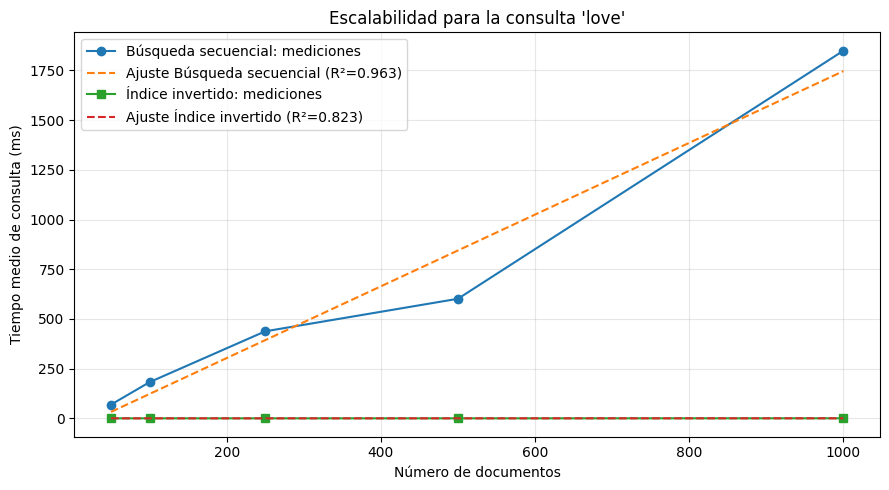

,a_ms_por_doc,b_ms,R2
método,,,
secuencial_ms,1.804472,-57.777335,0.962542
indice_ms,0.000267,-0.036169,0.823067


Interpretación: el barrido secuencial examina tokens de los documentos hasta hallar cada término,
por lo que su costo crece con el volumen total de texto. La consulta indexada hace una búsqueda
en el diccionario y recupera postings; con el índice ya construido suele variar mucho menos con n.
Este ajuste lineal describe únicamente los tamaños medidos y no sustituye un análisis asintótico.


In [17]:
if "scalability" in globals() and not scalability.empty:
    import numpy as np
    import matplotlib.pyplot as plt

    x = scalability["documentos"].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(9, 5))
    fits = {}
    for method, label, marker in [("secuencial_ms", "Búsqueda secuencial", "o"), ("indice_ms", "Índice invertido", "s")]:
        y = scalability[method].to_numpy(dtype=float)
        ax.plot(x, y, marker=marker, label=f"{label}: mediciones")
        if len(x) >= 2:
            a, b = np.polyfit(x, y, 1)
            predicted = a * x + b
            ss_res = np.sum((y - predicted) ** 2)
            ss_tot = np.sum((y - y.mean()) ** 2)
            r2 = 1 - ss_res / ss_tot if ss_tot else float("nan")
            fits[method] = {"a_ms_por_doc": a, "b_ms": b, "R2": r2}
            order = np.argsort(x)
            ax.plot(x[order], predicted[order], linestyle="--", label=f"Ajuste {label} (R²={r2:.3f})")
    ax.set(xlabel="Número de documentos", ylabel="Tiempo medio de consulta (ms)", title=f"Escalabilidad para la consulta {SCALABILITY_QUERY!r}")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    display(pd.DataFrame(fits).T.rename_axis("método"))
    print("""Interpretación: el barrido secuencial examina tokens de los documentos hasta hallar cada término,
por lo que su costo crece con el volumen total de texto. La consulta indexada hace una búsqueda
en el diccionario y recupera postings; con el índice ya construido suele variar mucho menos con n.
Este ajuste lineal describe únicamente los tamaños medidos y no sustituye un análisis asintótico.""")
else:
    print("Ejecute la sección 6 y luego esta sección para estimar t(n) y graficar.")